In [49]:
import numpy as np
import tensorflow as tf
from keras import Sequential
from keras.layers import LSTM, Dense, ConvLSTM2D
import matplotlib.pyplot as plt

In [50]:
with open('test_data_scaled.npy', 'rb') as f:
    Y = np.load(f)[1:]
with open('training_data_scaled.npy', 'rb') as f:
    X = np.load(f)[1:]
X = X.reshape(len(Y),10, 21)
X.shape, Y.shape

((3600, 10, 21), (3600, 21))

In [51]:
X[0]

array([[ 0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00],
       [ 0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
         1.000e+00],
       [ 5.100e+01,  9.000e+00,  3.000e+00,  1.000e+00,  1.471e+02,
         1.000e+03,  2.000e+03,  4.000e+03,  1.074e+04,  9.400e+03,
         1.469e+02, -3.000e+00, -6.000e+00, -9.000e+00, -3.400e+02,
         4.000e+03,  1.000e+03,  1.000e+03,  2.000e+03,  2.000e+03,
         0.000e+00],
       [-1.476e+03, -1.476e+03, -1.476e+03, -1.476e+03,  1.476e+02,
         0.000e+00,  0.000e+00,  0.000e+00,  0.000e+0

In [52]:
X.shape[1]

10

In [53]:
X[0].shape

(10, 21)

In [55]:
model = Sequential()
model.add(LSTM(21, input_shape=(X.shape[1], X.shape[2])))
#input_dim = input_dim, input_length = input_length
model.add(Dense(21))

def lr_scheduler(epoch, lr):
    if epoch < 20: return 1000.0
    if epoch<80:return 100.0
    if epoch < 160:return 10.0
    else: return 1.0
    
callbacks = [tf.keras.callbacks.LearningRateScheduler(lr_scheduler, verbose=0)]

model.compile(loss='mae', optimizer=tf.keras.optimizers.Adam())

history = model.fit(X, Y, epochs=200, batch_size=1000, validation_data=(X, Y), verbose=0, shuffle=False, callbacks=callbacks)

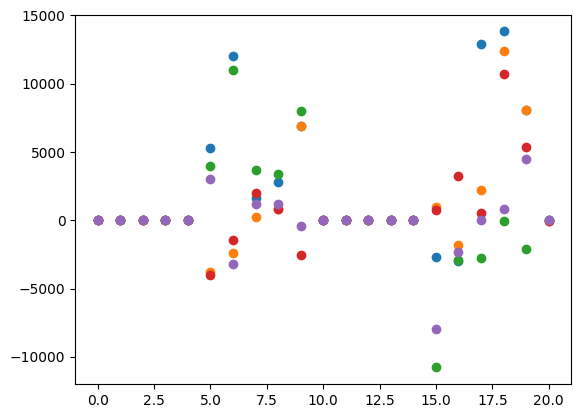

In [78]:
for i in [0,20,40,100,120]:
	plt.scatter(range(len(Y[i])), model.predict_on_batch(X[i:i+1])- Y[i])

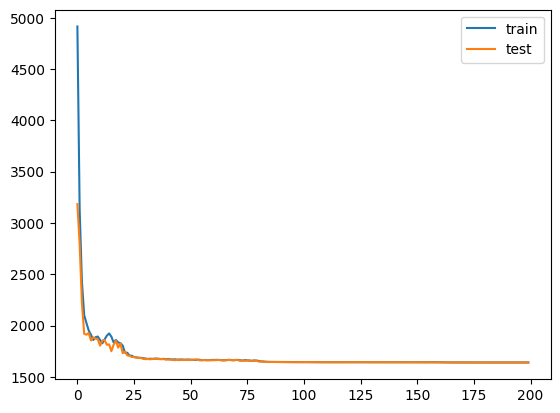

In [70]:
# plot history
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [71]:
model.count_params

<bound method Layer.count_params of <keras.engine.sequential.Sequential object at 0x00000290238D5B70>>